In [2]:
!apt-get install texlive texlive-xetex texlive-latex-extra pandoc
!pip install pypandoc



Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
pandoc is already the newest version (2.9.2.1-3ubuntu2).
pandoc set to manually installed.
The following additional packages will be installed:
  dvisvgm fonts-droid-fallback fonts-lato fonts-lmodern fonts-noto-mono fonts-texgyre
  fonts-urw-base35 libapache-pom-java libcommons-logging-java libcommons-parent-java
  libfontbox-java libfontenc1 libgs9 libgs9-common libidn12 libijs-0.35 libjbig2dec0 libkpathsea6
  libpdfbox-java libptexenc1 libruby3.0 libsynctex2 libteckit0 libtexlua53 libtexluajit2 libwoff1
  libzzip-0-13 lmodern poppler-data preview-latex-style rake ruby ruby-net-telnet ruby-rubygems
  ruby-webrick ruby-xmlrpc ruby3.0 rubygems-integration t1utils teckit tex-common tex-gyre
  texlive-base texlive-binaries texlive-fonts-recommended texlive-latex-base
  texlive-latex-recommended texlive-pictures texlive-plain-generic tipa xfonts-encodings
  xfonts-utils
Suggested packages:
  fo

In [3]:
!apt-get install cm-super


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  cm-super-minimal pfb2t1c2pfb
The following NEW packages will be installed:
  cm-super cm-super-minimal pfb2t1c2pfb
0 upgraded, 3 newly installed, 0 to remove and 18 not upgraded.
Need to get 26.0 MB of archives.
After this operation, 59.9 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 cm-super-minimal all 0.3.4-17 [5,777 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/universe amd64 pfb2t1c2pfb amd64 0.3-11 [9,342 B]
Get:3 http://archive.ubuntu.com/ubuntu jammy/universe amd64 cm-super all 0.3.4-17 [20.2 MB]
Fetched 26.0 MB in 1s (19.1 MB/s)
Selecting previously unselected package cm-super-minimal.
(Reading database ... 157713 files and directories currently installed.)
Preparing to unpack .../cm-super-minimal_0.3.4-17_all.deb ...
Unpacking cm-super-minimal (0.3.4-17) ...
Selecting 

In [4]:
!apt-get install dvipng


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  ghostscript
Suggested packages:
  ghostscript-x
The following NEW packages will be installed:
  dvipng ghostscript
0 upgraded, 2 newly installed, 0 to remove and 18 not upgraded.
Need to get 128 kB of archives.
After this operation, 414 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy-updates/main amd64 ghostscript amd64 9.55.0~dfsg1-0ubuntu5.5 [49.5 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/universe amd64 dvipng amd64 1.15-1.1 [78.9 kB]
Fetched 128 kB in 1s (205 kB/s)
Selecting previously unselected package ghostscript.
(Reading database ... 158174 files and directories currently installed.)
Preparing to unpack .../ghostscript_9.55.0~dfsg1-0ubuntu5.5_amd64.deb ...
Unpacking ghostscript (9.55.0~dfsg1-0ubuntu5.5) ...
Selecting previously unselected package dvipng.
Preparing to unpack .../dvipn

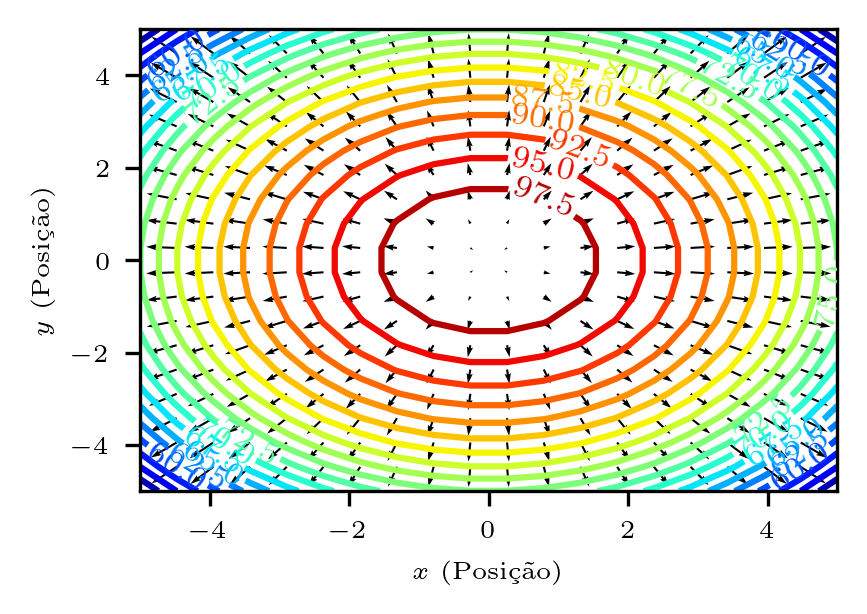

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Configurando a fonte para ser semelhante à fonte padrão do LaTeX
plt.rcParams["font.size"] = 6
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Computer Modern"]
plt.rcParams["text.usetex"] = True

# A função f(x, y) representa a distribuição de temperatura em um material.
def f(x, y):
    return -(x**2 + y**2) + 100

# O negativo do gradiente representa o vetor densidade de fluxo térmico.
def thermal_flux_density(x, y):
    dfdx = 2 * x
    dfdy = 2 * y
    return dfdx, dfdy

# Criando uma grade de valores para x e y
x = np.linspace(-5, 5, 20)
y = np.linspace(-5, 5, 20)

X, Y = np.meshgrid(x, y)
Z = f(X, Y)
U, V = thermal_flux_density(X, Y)

# Calculando a magnitude dos vetores e aplicando a escala logarítmica
magnitude = np.sqrt(U**2 + V**2)
log_magnitude = np.log(magnitude + 1e-16) # adicionando um pequeno valor para evitar log(0)

# Normalizando os vetores
U = U /magnitude
V = V /magnitude

# Multiplicando os vetores normalizados pela escala logarítmica para ajustar o comprimento
U *= log_magnitude
V *= log_magnitude

fig, ax = plt.subplots(figsize=(3, 2), dpi=300)

# Representação da distribuição de temperatura
contour_plot = ax.contour(X, Y, Z, 20, cmap="jet")

# Adicionando etiquetas às linhas de contorno
ax.clabel(contour_plot, inline=True, fontsize=8)

# Representação do vetor densidade de fluxo térmico
ax.quiver(X, Y, U, V, color='k', angles='xy', scale_units='xy', scale=5)

ax.set_xlabel(r"$x$ (Posição)")
ax.set_ylabel(r"$y$ (Posição)")

plt.savefig("gradiente.png", dpi=300)
plt.show()